# Lecture 6 — Class Exercise
## Choropleth Maps

> **Push to:** `week06/lecture06_exercise.ipynb`

**Rules:**
1. Use `px.choropleth` or `px.choropleth_map` — choose deliberately and state your reason
2. Right colour scale for your data (sequential vs diverging) — state which and why
3. Insight title names a geographic finding — not just a topic
4. `featureidkey` must be correctly matched to your GeoJSON

---


In [1]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import json


In [2]:
   import plotly.io as pio
   pio.renderers.default = "png"

## Task 1 — World choropleth: life expectancy diverging scale

**What to build:** A world choropleth showing **life expectancy relative to the global average** using a diverging colour scale.

**Requirements:**
- Use the Gapminder dataset for 2007: `px.data.gapminder()`
- Compute each country's deviation from the global mean life expectancy
- Diverging scale centred at zero (= world average)
- `hover_data` showing country name, raw life expectancy, and deviation
- Insight title naming which region is furthest below average

> 💡 `gm_2007['lifeExp'].mean()` gives you the global average to subtract from


Global mean life expectancy 2007: 67.0 years
continent
Africa     -12.2
Asia         3.7
Americas     6.6
Europe      10.6
Oceania     13.7
Name: deviation, dtype: float64


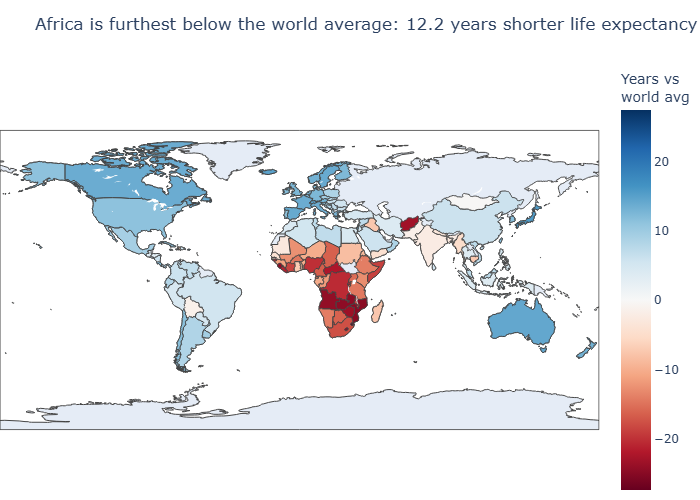

In [3]:
# Task 1
gm = px.data.gapminder()
gm_2007 = gm[gm['year'] == 2007].copy()

# Deviation from the global (unweighted, country-level) mean life expectancy
global_mean = gm_2007['lifeExp'].mean()
gm_2007['deviation'] = gm_2007['lifeExp'] - global_mean

# Which region is furthest below average?
region_gap = gm_2007.groupby('continent')['deviation'].mean().sort_values()
worst_region, worst_gap = region_gap.index[0], region_gap.iloc[0]
print(f"Global mean life expectancy 2007: {global_mean:.1f} years")
print(region_gap.round(1))

fig1 = px.choropleth(
    gm_2007,
    locations='iso_alpha',               # built-in country shapes, no GeoJSON needed
    color='deviation',
    hover_name='country',
    hover_data={
        'iso_alpha': False,
        'continent': True,
        'lifeExp': ':.1f',
        'deviation': ':+.1f',
    },
    color_continuous_scale='RdBu',       # diverging: red = below, blue = above average
    color_continuous_midpoint=0,         # 0 = world average sits at the neutral colour
    labels={'lifeExp': 'Life expectancy (years)',
            'deviation': 'Vs. world average (years)',
            'continent': 'Region'},
    title=(f"{worst_region} is furthest below the world average: "
           f"{abs(worst_gap):.1f} years shorter life expectancy in 2007 "
           f"(world mean {global_mean:.1f})"),
)
fig1.update_layout(coloraxis_colorbar=dict(title='Years vs<br>world avg'),
                   margin=dict(l=0, r=0, t=60, b=0))
fig1.show()

## Task 2 — Find your own GeoJSON

**What to build:** A choropleth using a GeoJSON file you find yourself online.

**Requirements:**
- Find a free GeoJSON file for any geography that interests you (country, region, city)
- Create or find a matching dataset with at least one numeric variable per region
- Build either a `px.choropleth` or `px.choropleth_mapbox` — state your choice and reason in the markdown cell below
- Correctly identify and set `featureidkey` by inspecting the GeoJSON properties
- Choose sequential or diverging scale — state your reason in the markdown cell below
- Insight title naming a geographic finding

**Where to find GeoJSON files:**
- [geojson.xyz](https://geojson.xyz/) — countries, cities, natural features
- [naturalearthdata.com](https://www.naturalearthdata.com/) — global admin boundaries
- [github.com/datasets/geo-countries](https://github.com/datasets/geo-countries) — country polygons
- Search: `[country name] [admin level] GeoJSON github` — most countries have free boundary files on GitHub

> 💡 Before plotting, always inspect your GeoJSON properties first:
> ```python
> print(my_geojson['features'][0]['properties'])
> ```
> The property name that matches your dataframe's location column is what goes in `featureidkey='properties.???'`


### Task 2 — Design decisions

**GeoJSON source:** German federal states (Bundesländer) from the open-source repo [isellsoap/deutschlandGeoJSON](https://github.com/isellsoap/deutschlandGeoJSON) (`2_bundeslaender/2_hoch.geo.json`, 16 polygons).

**Chart type chosen** (`px.choropleth` or `px.choropleth_mapbox`) **and reason:**

`px.choropleth_map` (the current MapLibre-based replacement for `px.choropleth_mapbox`, which is deprecated). The regions are custom polygons from my own GeoJSON, and a street-level basemap with zoom and pan lets the reader locate each state against real geography (coast, neighbouring countries). It also needs no Mapbox token. `px.choropleth` would work too, but it relies on the geo projection and has no base tiles, so it is better suited to world or country-level maps like Task 1.

**Colour scale chosen** (sequential or diverging) **and reason:**

**Sequential** (`YlOrRd`). Population density is a quantity that runs from low to high with no meaningful neutral midpoint, so a single-hue-family light-to-dark scale encodes "more" as "darker". A diverging scale would imply a meaningful centre that this data doesn't have. Because the three city-states are 10-20x denser than everything else, I colour by log10(density) and relabel the colour bar with real values, otherwise 13 of 16 states would look identical.

**Data note:** population is approximate (31 Dec 2023, rounded to 10,000s, Destatis) and area in km² is rounded. Verify against destatis.de before citing.

16 features
{'id': 'DE-BW', 'name': 'Baden-Württemberg', 'type': 'State'}
featureidkey = properties.name


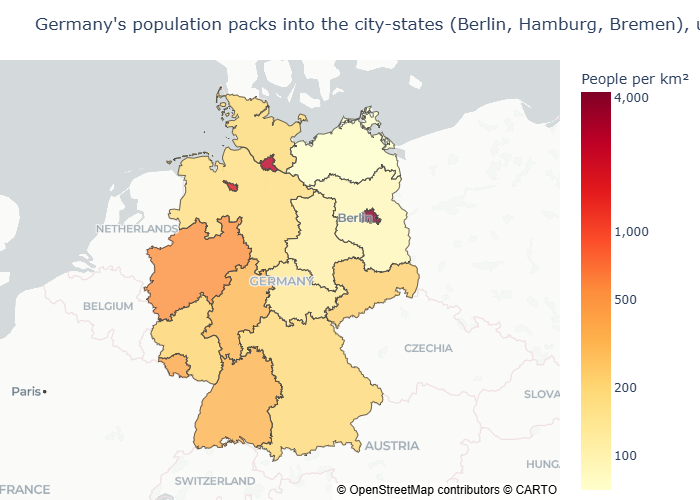

In [4]:
# Task 2
import os
import urllib.request
import numpy as np

# --- 1. Load the GeoJSON ------------------------------------------------------
GEO_URL = ("https://raw.githubusercontent.com/isellsoap/deutschlandGeoJSON/"
           "main/2_bundeslaender/2_hoch.geo.json")
GEO_FILE = 'germany_states.geojson'
if not os.path.exists(GEO_FILE):
    urllib.request.urlretrieve(GEO_URL, GEO_FILE)

with open(GEO_FILE, 'r', encoding='utf-8') as file:
    my_geojson = json.load(file)

# --- 2. Inspect the properties to find the right featureidkey -----------------
print(len(my_geojson['features']), 'features')
print(my_geojson['features'][0]['properties'])

# --- 3. Matching dataset: population density per state ------------------------
# population: approx. 31 Dec 2023 (Destatis), area in km2 (rounded)
states = {
    'Baden-Württemberg':      (11_280_000, 35_748),
    'Bayern':                 (13_440_000, 70_542),
    'Berlin':                 (3_780_000,     891),
    'Brandenburg':            (2_570_000, 29_654),
    'Bremen':                 (720_000,       420),
    'Hamburg':                (1_890_000,     755),
    'Hessen':                 (6_390_000, 21_116),
    'Mecklenburg-Vorpommern': (1_630_000, 23_295),
    'Niedersachsen':          (8_140_000, 47_710),
    'Nordrhein-Westfalen':    (18_140_000, 34_112),
    'Rheinland-Pfalz':        (4_160_000, 19_858),
    'Saarland':               (990_000,    2_572),
    'Sachsen':                (4_090_000, 18_450),
    'Sachsen-Anhalt':         (2_180_000, 20_455),
    'Schleswig-Holstein':     (2_950_000, 15_804),
    'Thüringen':              (2_110_000, 16_202),
}
df = pd.DataFrame(
    [(s, p, a) for s, (p, a) in states.items()],
    columns=['state', 'population', 'area_km2'],
)
df['density'] = (df['population'] / df['area_km2']).round(0)
df['log10_density'] = np.log10(df['density'])

# --- 4. Pick featureidkey by checking which property matches the dataframe ----
def norm(x):
    return str(x).strip().lower()

wanted = {norm(s) for s in df['state']}
candidate_keys = [
    k for k in my_geojson['features'][0]['properties']
    if wanted <= {norm(f['properties'].get(k)) for f in my_geojson['features']}
]
if not candidate_keys:
    raise ValueError("No GeoJSON property matches the state names - check the printed "
                     "properties above and adjust the names in `states`.")
key = 'name' if 'name' in candidate_keys else candidate_keys[0]
featureidkey = f'properties.{key}'
print('featureidkey =', featureidkey)

# use the GeoJSON's exact spelling as the location id
lookup = {norm(f['properties'][key]): f['properties'][key] for f in my_geojson['features']}
df['geo_id'] = df['state'].map(lambda s: lookup[norm(s)])

# --- 5. Insight title from the data -------------------------------------------
top3 = df.nlargest(3, 'density')['state'].tolist()
lowest = df.loc[df['density'].idxmin()]
ratio = df['density'].max() / df['density'].min()
title = (f"Germany's population packs into the city-states ({', '.join(top3)}), "
         f"up to {ratio:.0f}x denser than {lowest['state']} ({lowest['density']:.0f} people/km²)")

# --- 6. Map -------------------------------------------------------------------
fig2 = px.choropleth_map(
    df,
    geojson=my_geojson,
    locations='geo_id',
    featureidkey=featureidkey,
    color='log10_density',
    color_continuous_scale='YlOrRd',     # sequential
    hover_name='state',
    hover_data={'geo_id': False, 'log10_density': False,
                'density': ':,.0f', 'population': ':,.0f', 'area_km2': ':,.0f'},
    labels={'density': 'People per km²', 'population': 'Population', 'area_km2': 'Area (km²)'},
    map_style='carto-positron',
    center={'lat': 51.2, 'lon': 10.4},
    zoom=4.4,
    opacity=0.8,
    title=title,
)
tick_vals = [50, 100, 200, 500, 1000, 4000]
fig2.update_coloraxes(colorbar=dict(
    title='People per km²',
    tickvals=np.log10(tick_vals),
    ticktext=[f'{v:,}' for v in tick_vals],
))
fig2.update_layout(margin=dict(l=0, r=0, t=60, b=0))
fig2.show()